# Patas RR: ángulos de los eslabones, animación y geometría

Lado derecho: pata delantera (FR) y trasera (BR). Cada pata tiene 6 eslabones en el plano sagital:

| Eslabón | Qué es | Color |
|---|---|---|
| tibia | pivote de la rodilla O → tobillo J | gris oscuro |
| metatarso | tobillo J → pie | gris |
| l1, l2 | RR 1: manivela en B (motor `rr1`) → codo → punto f1 de la tibia | naranja |
| l3, l4 | RR 2: manivela en O (motor `rr2`) → codo → punto f2 del metatarso | rojo |

Los ángulos son absolutos en el marco del torso: se miden desde el eje longitudinal del torso (hacia adelante),
positivos hacia arriba, así que un eslabón vertical hacia abajo está en −90°, uno horizontal hacia adelante en 0° y
uno horizontal hacia atrás en −180°.

**Secciones 1–3: agente `17-37-28`** (1.40 m/s, geometría actual con todo el montaje dentro del torso, referencia
trasera sin doble bajada, penalización de límites, suavidad y seguimiento de la posición/velocidad de los pies).
Otros agentes: `16-41-28` (misma geometría, sin seguimiento de pies), `10-10-34` (geometría anterior). Sus datos salen de una corrida determinista que
arranca en el primer cuadro de la referencia (agente y referencia en fase), guardada en `rollout_16-41-28.npz`;
solo se recalcula si falta (necesita la GPU). Para ver el agente anterior (`10-10-34`, geometría anterior) cambia
`RUN` a `"10-10-34"`: su XML está copiado aquí (`senecabot_loco_rr_10-10-34.xml`).

**Secciones 4–5: geometría actual y referencia trasera corregida**
(`seneca_loco/simulation/assets/xml/senecabot_loco_rr.xml`).

In [1]:
import subprocess
from pathlib import Path

import matplotlib.pyplot as plt
import mujoco
import numpy as np
from IPython.display import Image, display
from matplotlib import animation
from matplotlib.patches import Circle, Polygon

REPO = Path.cwd().resolve().parent                     # Definicion-Senecabot/
SENECA = REPO / "seneca_loco"
RUN = "17-37-28"                                       # agente (artifacts/trained_agents_rr/2026-11-04/<RUN>)
XML_NOW = SENECA / "simulation/assets/xml/senecabot_loco_rr.xml"
XML_AGENT = Path(f"senecabot_loco_rr_{RUN}.xml") if RUN == "10-10-34" else XML_NOW   # geometría del agente
AGENT = SENECA / f"artifacts/trained_agents_rr/2026-11-04/{RUN}/PPOJax_final.pkl"
ROLLOUT = Path(f"rollout_{RUN}.npz")
REF_NOW = SENECA / "data/processed_data/trajectory_adapted_rr_1p40.npz"     # referencia actual (corregida)
REF_DIP = Path("ref_1p40_con_doble_bajada.npz")        # misma geometría, sin corregir la doble bajada trasera
N_STEPS = 400                                          # 4 s a 100 Hz
SIDE = "r"                                             # "r" = FR + BR, "l" = FL + BL
LEGS = ("f" + SIDE, "b" + SIDE)
LEG_NAME = {LEGS[0]: "delantera", LEGS[1]: "trasera"}

if not ROLLOUT.exists():                               # corrida del agente (MjWarp, GPU)
    script = (
        "import sys, numpy as np; sys.path.insert(0, 'simulation/training'); import eval_rr; "
        f"r = eval_rr.rollout_qpos('{AGENT}', {N_STEPS}); np.savez('{ROLLOUT.resolve()}', **r)")
    subprocess.run(["python", "-c", script], cwd=SENECA, check=True, capture_output=True)

R = np.load(ROLLOUT)
Q, QREF, DT = R["qpos"], R["qpos_ref"], float(R["dt"])
t = np.arange(len(Q)) * DT
print(f"{len(Q)} pasos ({t[-1] + DT:.1f} s), caídas: {int(R['absorbing'].sum())}")

400 pasos (4.0 s), caídas: 0


## Cinemática directa

Para cada cuadro se calcula con MuJoCo (CPU) la posición de los puntos de cada pata. Las barras son cápsulas a lo
largo del eje x de su cuerpo, así que su punta es el origen del cuerpo + largo × eje x.

In [2]:
LINKS = {"tibia": ("O", "J"), "metatarso": ("J", "P"), "l1": ("B", "K1"), "l2": ("K1", "Q1"),
         "l3": ("O", "K2"), "l4": ("K2", "Q2")}
COLORS = {"tibia": "0.15", "metatarso": "0.55", "l1": "#e68a00", "l2": "#f5b942", "l3": "#c0392b", "l4": "#e57368"}


class Rig:
    """Modelo MuJoCo + cinemática directa de las patas de un lado."""

    def __init__(self, xml):
        xml = Path(xml)                                # includes (scene.xml, ...) viven junto al XML del modelo
        assets = {f.name: f.read_bytes() for f in XML_NOW.parent.glob("*.xml")}
        self.m = mujoco.MjModel.from_xml_string(xml.read_text(), assets)
        self.d = mujoco.MjData(self.m)
        m = self.m
        box = [g for g in range(m.ngeom) if m.geom_bodyid[g] == m.body("base").id
               and m.geom_type[g] == mujoco.mjtGeom.mjGEOM_BOX][0]
        self.half = m.geom_size[box]                   # medio largo, medio ancho, medio alto del torso
        self.length = {(leg, b): 2 * m.geom_size[[g for g in range(m.ngeom) if m.geom_bodyid[g] == m.body(f"{leg}_{b}").id][0]][1]
                       for leg in LEGS for b in ("rr1_l2", "rr2_l4")}

    def points(self, qpos):
        """Puntos de las patas en el mundo (x, z) y en el marco del torso, más la pose del torso."""
        m, d = self.m, self.d
        d.qpos[:] = qpos
        mujoco.mj_kinematics(m, d)
        bid = lambda n: m.body(n).id
        base_p, base_R = d.xpos[bid("base")].copy(), d.xmat[bid("base")].reshape(3, 3).copy()
        world, local = {}, {}
        for leg in LEGS:
            p = {"O": d.xpos[bid(f"{leg}_lower")], "J": d.xpos[bid(f"{leg}_foot")],
                 "P": d.site_xpos[m.site(f"{leg}_foot_mimic").id],
                 "B": d.xpos[bid(f"{leg}_rr1_l1")], "K1": d.xpos[bid(f"{leg}_rr1_l2")],
                 "K2": d.xpos[bid(f"{leg}_rr2_l4")]}
            p["Q1"] = p["K1"] + self.length[leg, "rr1_l2"] * d.xmat[bid(f"{leg}_rr1_l2")].reshape(3, 3)[:, 0]
            p["Q2"] = p["K2"] + self.length[leg, "rr2_l4"] * d.xmat[bid(f"{leg}_rr2_l4")].reshape(3, 3)[:, 0]
            world[leg] = {k: v[[0, 2]].copy() for k, v in p.items()}
            local[leg] = {k: (base_R.T @ (v - base_p))[[0, 2]] for k, v in p.items()}
        return world, local, base_p, base_R

    def link_angles(self, qpos_seq):
        """Ángulo [deg] de cada eslabón respecto al eje x del torso: {leg: {link: [T]}}."""
        out = {leg: {k: [] for k in LINKS} for leg in LEGS}
        for q in qpos_seq:
            _, loc, _, _ = self.points(q)
            for leg in LEGS:
                for k, (a, b) in LINKS.items():
                    dv = loc[leg][b] - loc[leg][a]
                    out[leg][k].append(np.arctan2(dv[1], dv[0]))

        def center(v):                                 # misma vuelta para todos: media en (-270°, 90°]
            v = np.degrees(np.unwrap(v))
            return v - 360 * np.round((v.mean() + 90) / 360)
        return {leg: {k: center(v) for k, v in links.items()} for leg, links in out.items()}

    def qadr(self, joint):
        return self.m.jnt_qposadr[self.m.joint(joint).id]


rig = Rig(XML_AGENT)
ANG, ANG_REF = rig.link_angles(Q), rig.link_angles(QREF)
print({leg: {k: f"{v.min():.0f}..{v.max():.0f}" for k, v in ANG[leg].items()} for leg in LEGS})

{'fr': {'tibia': '-37..7', 'metatarso': '-184..-80', 'l1': '-32..37', 'l2': '-61..-39', 'l3': '-175..-80', 'l4': '-36..9'}, 'br': {'tibia': '-163..-137', 'metatarso': '-124..-70', 'l1': '-99..-11', 'l2': '-143..-119', 'l3': '-135..-101', 'l4': '-192..-167'}}


## 1. Ángulos articulares: knee y ankle, agente vs referencia

Estos son los dos ángulos que imita el agente. En el modelo RR, knee = −(ángulo absoluto de la tibia respecto al
torso) y ankle = ángulo del metatarso respecto a la tibia. Las líneas rojas finas son los límites articulares.

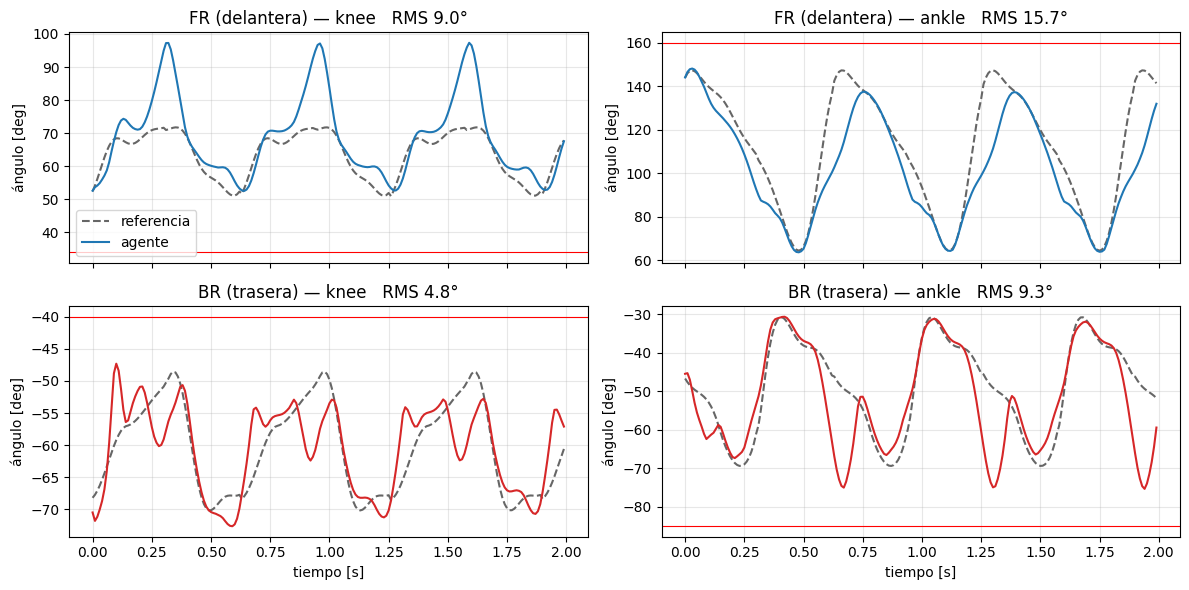

In [3]:
T_SHOW = min(len(Q), 200)                              # 2 s ≈ 3 ciclos de 0.635 s

fig, axes = plt.subplots(2, 2, figsize=(12, 6), sharex=True)
for i, leg in enumerate(LEGS):
    for j, jn in enumerate(("knee", "ankle")):
        ax, a = axes[i, j], rig.qadr(f"{leg}_{jn}_joint")
        ax.plot(t[:T_SHOW], np.degrees(QREF[:T_SHOW, a]), "--", color="0.4", label="referencia")
        ax.plot(t[:T_SHOW], np.degrees(Q[:T_SHOW, a]), color="C0" if i == 0 else "C3", label="agente")
        lo, hi = np.degrees(rig.m.jnt_range[rig.m.joint(f"{leg}_{jn}_joint").id])
        for lim in (lo, hi):
            if ax.get_ylim()[0] - 15 < lim < ax.get_ylim()[1] + 15:
                ax.axhline(lim, color="r", lw=0.8)
        rms = np.degrees(np.sqrt(np.mean((Q[:, a] - QREF[:, a]) ** 2)))
        ax.set_title(f"{leg.upper()} ({LEG_NAME[leg]}) — {jn}   RMS {rms:.1f}°")
        ax.set_ylabel("ángulo [deg]")
        ax.grid(alpha=0.3)
axes[0, 0].legend()
for ax in axes[-1]:
    ax.set_xlabel("tiempo [s]")
fig.tight_layout()
plt.show()

## 2. Ángulos absolutos de los 6 eslabones de cada pata

Línea continua: agente; discontinua: referencia (las barras de la referencia salen de la cinemática inversa del
mecanismo, así que es el movimiento que tendrían los RR si la pata siguiera la referencia exactamente).

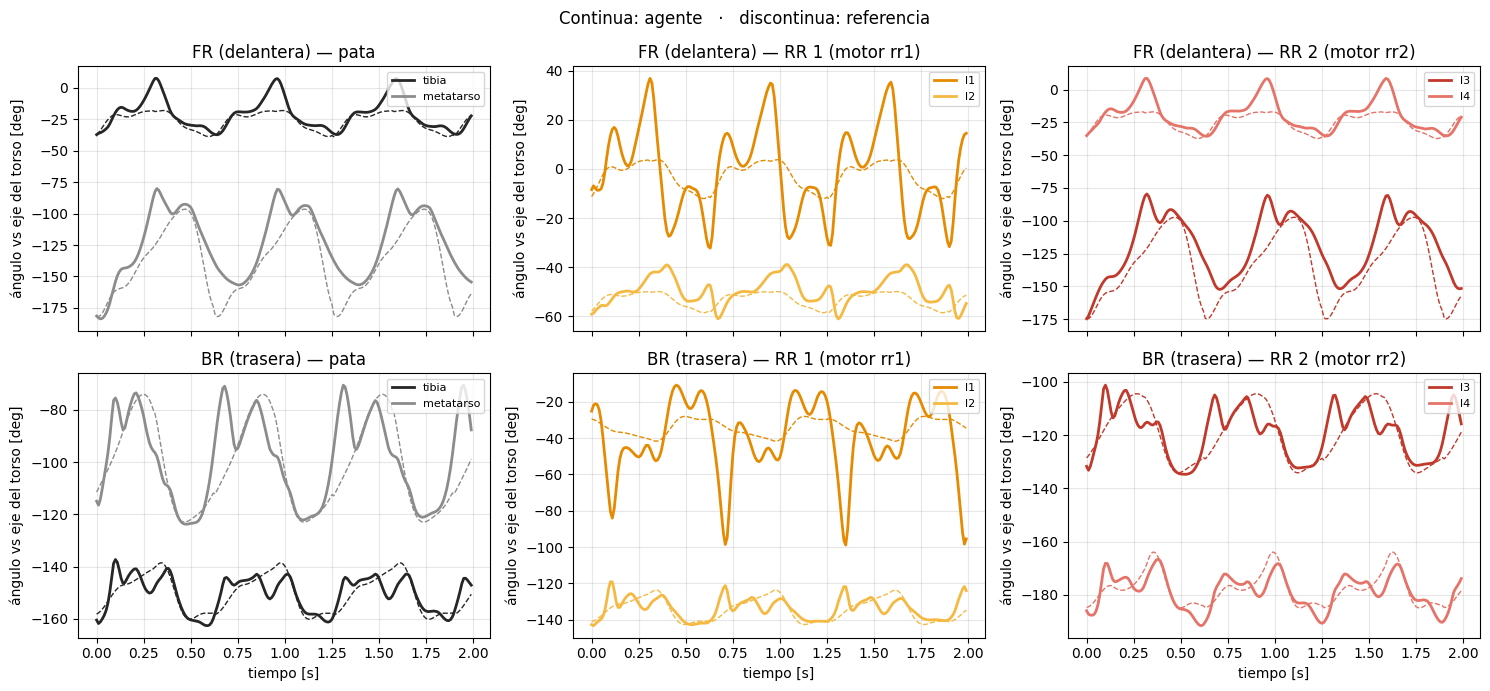

Rango de movimiento del agente [deg] (p1–p99):
  FR: tibia 44, metatarso 101, l1 66, l2 22, l3 81, l4 44
  BR: tibia 21, metatarso 53, l1 85, l2 21, l3 31, l4 23


In [4]:
GROUPS = {"pata": ("tibia", "metatarso"), "RR 1 (motor rr1)": ("l1", "l2"), "RR 2 (motor rr2)": ("l3", "l4")}

fig, axes = plt.subplots(2, 3, figsize=(15, 7), sharex=True)
for i, leg in enumerate(LEGS):
    for j, (title, links) in enumerate(GROUPS.items()):
        ax = axes[i, j]
        for k in links:
            ax.plot(t[:T_SHOW], ANG[leg][k][:T_SHOW], color=COLORS[k], lw=2, label=k)
            ax.plot(t[:T_SHOW], ANG_REF[leg][k][:T_SHOW], "--", color=COLORS[k], lw=1)
        ax.set_title(f"{leg.upper()} ({LEG_NAME[leg]}) — {title}")
        ax.set_ylabel("ángulo vs eje del torso [deg]")
        ax.grid(alpha=0.3)
        ax.legend(loc="upper right", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("tiempo [s]")
fig.suptitle("Continua: agente   ·   discontinua: referencia")
fig.tight_layout()
plt.show()

print("Rango de movimiento del agente [deg] (p1–p99):")
for leg in LEGS:
    print(f"  {leg.upper()}: " + ", ".join(f"{k} {np.ptp(np.percentile(v, [1, 99])):.0f}"
                                          for k, v in ANG[leg].items()))

## 3. Animación: pata delantera y trasera unidas por el torso

Vista lateral del lado derecho; la cámara sigue al torso en x. Con la geometría actual todos los pivotes de montaje
quedan dentro del torso (con la del agente `10-10-34` se dibuja además la placa bajo el torso que sostenía la rodilla
delantera). El GIF va a mitad de velocidad (2 pasos de 10 ms por cuadro, 25 cuadros/s).

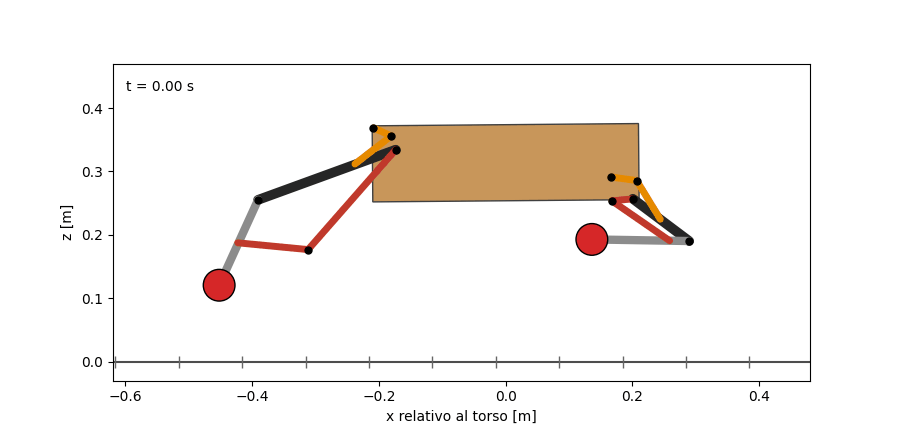

In [5]:
TORSO_C = "#c8965a"
STYLE = {"tibia": (COLORS["tibia"], 7), "metatarso": (COLORS["metatarso"], 6), "l1": (COLORS["l1"], 5),
         "l2": (COLORS["l1"], 5), "l3": (COLORS["l3"], 5), "l4": (COLORS["l3"], 5)}


class Drawing:
    """Dibujo 2D (vista lateral) del torso y de las patas de un lado, centrado en el torso en x."""

    def __init__(self, ax, rig, labels=False):
        self.ax, self.rig, self.labels = ax, rig, labels
        ax.set_aspect("equal")
        ax.axhline(0, color="0.3", lw=1.5)
        ax.set_xlabel("x relativo al torso [m]")
        ax.set_ylabel("z [m]")
        self.torso = ax.add_patch(Polygon(np.zeros((4, 2)), closed=True, fc=TORSO_C, ec="0.25", zorder=3))
        self.plate, = ax.plot([], [], color=TORSO_C, lw=5, solid_capstyle="butt", zorder=2)
        self.lines = {(leg, k): ax.plot([], [], color=STYLE[k][0], lw=STYLE[k][1], solid_capstyle="round",
                                        zorder=4)[0] for leg in LEGS for k in LINKS}
        self.pivots, = ax.plot([], [], "o", color="k", ms=5, zorder=6)
        self.feet = [ax.add_patch(Circle((0, 0), 0.025, fc="#d62728", ec="k", zorder=5)) for _ in LEGS]
        self.marks, = ax.plot([], [], "|", color="0.4", ms=8)
        self.texts = []

    def draw(self, qpos):
        world, _, base_p, base_R = self.rig.points(qpos)
        x0 = base_p[0]
        hx, _, hz = self.rig.half
        corners = np.array([[-hx, 0, -hz], [hx, 0, -hz], [hx, 0, hz], [-hx, 0, hz]])
        c = (base_R @ corners.T).T + base_p
        self.torso.set_xy(np.c_[c[:, 0] - x0, c[:, 2]])
        under = (base_p + base_R @ np.array([0, 0, -hz]))[2]
        O_front = world[LEGS[0]]["O"]
        if O_front[1] < under - 1e-4:                  # montaje bajo el torso (geometría vieja)
            self.plate.set_data([O_front[0] - x0] * 2, [O_front[1], under])
        piv = []
        for n, leg in enumerate(LEGS):
            p = {k: v - [x0, 0] for k, v in world[leg].items()}
            for k, (a, b) in LINKS.items():
                self.lines[leg, k].set_data([p[a][0], p[b][0]], [p[a][1], p[b][1]])
            piv += [p["B"], p["O"], p["J"], p["K1"], p["K2"]]
            self.feet[n].center = p["P"]
            if self.labels:
                for name, off in (("O", (0.012, -0.022)), ("B", (-0.035, 0.012))):
                    self.texts.append(self.ax.text(*(p[name] + off), f"{name}$_{{{leg.upper()}}}$", fontsize=9,
                                                   zorder=7))
        piv = np.array(piv)
        self.pivots.set_data(piv[:, 0], piv[:, 1])
        m = np.arange(np.floor((x0 - 0.7) / 0.1), np.ceil((x0 + 0.6) / 0.1)) * 0.1 - x0
        self.marks.set_data(m, np.zeros_like(m))
        return [self.torso, self.plate, self.pivots, self.marks, *self.lines.values(), *self.feet]


STRIDE, FPS = 2, 25
GIF = Path(f"patas_rr_{RUN}.gif")
fig, ax = plt.subplots(figsize=(9, 4.4))
ax.set_xlim(-0.62, 0.48)
ax.set_ylim(-0.03, 0.47)
drawing = Drawing(ax, rig)
label = ax.text(0.02, 0.95, "", transform=ax.transAxes, va="top")


def frame(i):
    label.set_text(f"t = {t[i]:.2f} s")
    return [*drawing.draw(Q[i]), label]


anim = animation.FuncAnimation(fig, frame, frames=range(0, T_SHOW, STRIDE), blit=True)
anim.save(GIF, writer=animation.PillowWriter(fps=FPS))
plt.close(fig)
display(Image(filename=str(GIF)))

## 4. Geometría actual (sin entrenar)

Geometría regenerada con `geometry_opt/make_rr_xml.py` para que **ninguna parte del montaje quede fuera del
rectángulo del torso**:

- Pata delantera: el pivote de la rodilla O (inicio de la tibia) y el pivote de la manivela B quedan dentro del
  torso, sin placa de montaje (antes O colgaba 3.5 cm bajo el torso con una placa).
- Pata trasera: la pata se corrió hacia adelante lo justo para que el origen B del RR naranja quede dentro del torso
  (antes estaba 2.5 cm detrás del borde).
- Se mantiene la diferencia de altura entre las rodillas delantera y trasera que deja el torso recto en la marcha
  (8.06 cm), así que la referencia sigue con inclinación 0°.

Las poses son de la referencia actual de 1.40 m/s: el cuadro donde el pie delantero está apoyado y el cuadro donde
lo está el trasero. Los pivotes O y B de cada pata están rotulados.

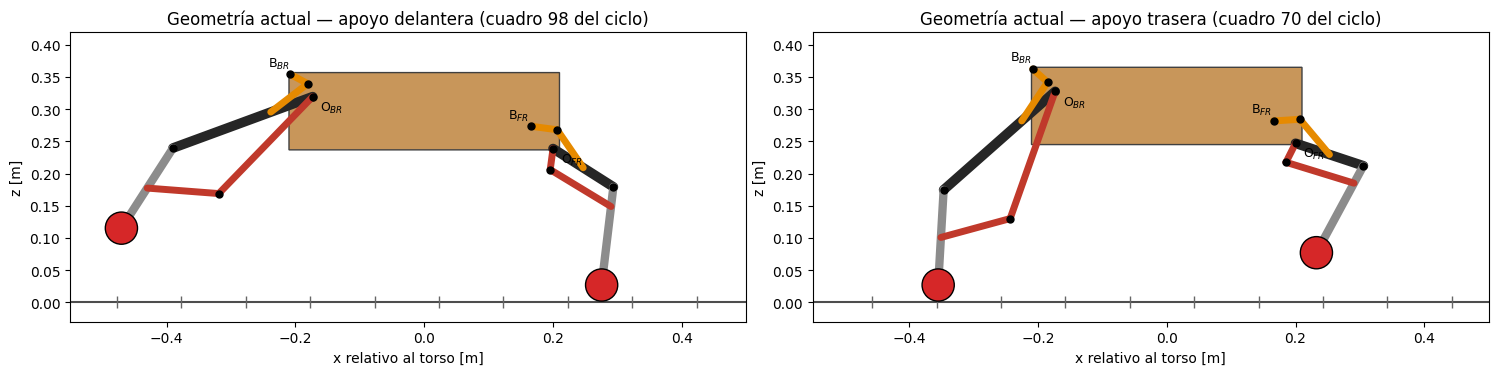

torso: x ∈ [-0.210, 0.210], z ∈ [-0.060, 0.060] m (marco del torso)
  FR O: x = +0.2000, z = -0.0580  -> dentro del torso
  FR B: x = +0.1658, z = -0.0233  -> dentro del torso
  BR O: x = -0.1733, z = +0.0226  -> dentro del torso
  BR B: x = -0.2080, z = +0.0573  -> dentro del torso


In [6]:
rig_now = Rig(XML_NOW)
QNOW = np.load(REF_NOW)["qpos"]


def foot_z(rig, qseq, leg):
    out = []
    for q in qseq:
        world, _, _, _ = rig.points(q)
        out.append(world[leg]["P"][1])
    return np.array(out)


cycle = QNOW[:127]                                     # un ciclo (0.635 s)
poses = {f"apoyo {LEG_NAME[leg]}": int(np.argmin(foot_z(rig_now, cycle, leg))) for leg in LEGS}

fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, (title, i) in zip(axes, poses.items()):
    ax.set_xlim(-0.55, 0.5)
    ax.set_ylim(-0.03, 0.42)
    Drawing(ax, rig_now, labels=True).draw(cycle[i])
    ax.set_title(f"Geometría actual — {title} (cuadro {i} del ciclo)")
fig.tight_layout()
fig.savefig("geometria_rr_actual.png", dpi=120)
plt.show()

hx, _, hz = rig_now.half
_, loc, _, _ = rig_now.points(cycle[0])
print(f"torso: x ∈ [{-hx:.3f}, {hx:.3f}], z ∈ [{-hz:.3f}, {hz:.3f}] m (marco del torso)")
for leg in LEGS:
    for k in ("O", "B"):
        x, z = loc[leg][k]
        inside = abs(x) <= hx and abs(z) <= hz
        print(f"  {leg.upper()} {k}: x = {x:+.4f}, z = {z:+.4f}  -> {'dentro' if inside else 'FUERA'} del torso")

## 5. Referencia trasera corregida: sin doble bajada

En la referencia, el pie trasero bajaba hasta ~2.7 cm del suelo, volvía a subir ~1.7 cm y recién entonces apoyaba.
La recompensa de contacto lo contaba como dos apoyos por ciclo y el agente lo exageraba: dos picos rápidos de rodilla
por ciclo. En `trajectory_generation_rr.py` (`flatten_double_dip`) solo se cambia esa joroba: desde el primer punto
bajo del descenso, el pie ya no vuelve a subir y empalma (curva cúbica, misma pendiente en la unión) con el descenso
original hacia el apoyo; la posición horizontal no cambia y knee/ankle de ese tramo salen de la cinemática inversa
del pie. Fuera de la joroba la referencia es idéntica a la original. El tobillo, que en la joroba bajaba a −80°
(límite −85°), queda en −69°; además la recompensa penaliza acercarse a menos de 5° de cualquier límite
(`joint_limit_w`).

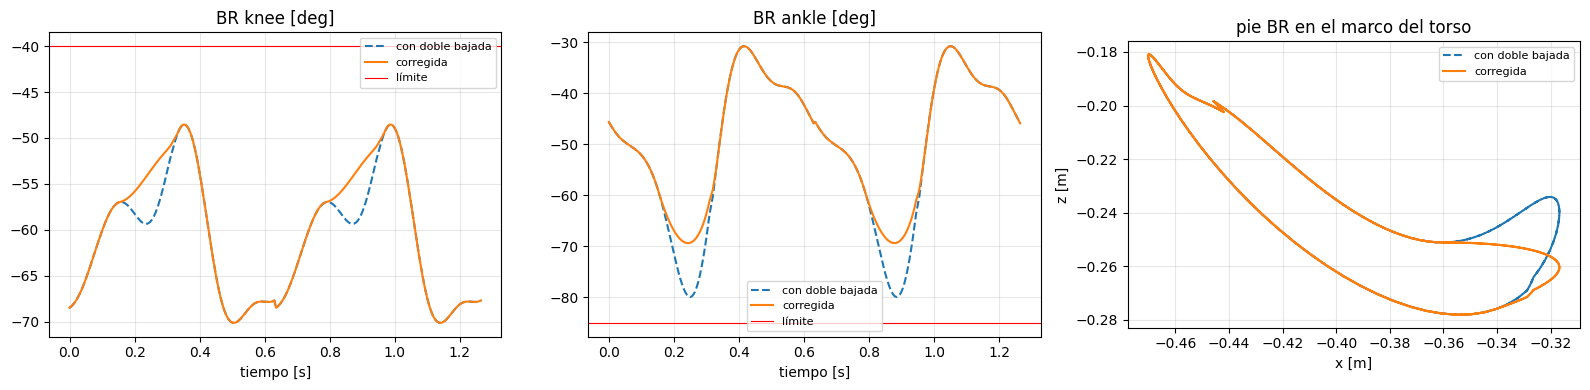

con doble bajada : desviación RMS vs original knee/ankle 0.0/0.0°, re-subida del pie al bajar 22.6 mm, aceleración RMS knee/ankle 44/81 rad/s², ankle mínimo -79.9°
corregida        : desviación RMS vs original knee/ankle 1.8/3.5°, re-subida del pie al bajar 2.5 mm, aceleración RMS knee/ankle 40/69 rad/s², ankle mínimo -69.4°


In [7]:
QDIP = np.load(REF_DIP)["qpos"][:254]
QFIX = QNOW[:254]
tt = np.arange(254) / 200                              # la referencia está a 200 Hz
leg = LEGS[1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for qs, lab, st in ((QDIP, "con doble bajada", "--"), (QFIX, "corregida", "-")):
    for ax, jn in zip(axes[:2], ("knee", "ankle")):
        ax.plot(tt, np.degrees(qs[:, rig_now.qadr(f"{leg}_{jn}_joint")]), st, label=lab)
    pts = np.array([rig_now.points(q)[1][leg]["P"] for q in qs])
    axes[2].plot(pts[:, 0], pts[:, 1], st, label=lab)
for ax, jn in zip(axes[:2], ("knee", "ankle")):
    lo, hi = np.degrees(rig_now.m.jnt_range[rig_now.m.joint(f"{leg}_{jn}_joint").id])
    ax.axhline(hi if jn == "knee" else lo, color="r", lw=0.8, label="límite")
    ax.set_title(f"{leg.upper()} {jn} [deg]")
    ax.set_xlabel("tiempo [s]")
axes[2].set_title(f"pie {leg.upper()} en el marco del torso")
axes[2].set_xlabel("x [m]")
axes[2].set_ylabel("z [m]")
axes[2].set_aspect("equal")
for ax in axes:
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8)
fig.tight_layout()
plt.show()

for qs, lab in ((QDIP, "con doble bajada"), (QFIX, "corregida")):
    z = foot_z(rig_now, qs[:127], leg)
    i_apex, i_min = int(np.argmax(z)), int(np.argmin(z))
    desc = z[(i_apex + np.arange((i_min - i_apex) % len(z) + 1)) % len(z)]     # descenso: punto más alto -> apoyo
    rerise = 1000 * np.max(desc - np.minimum.accumulate(desc))
    acc = [np.sqrt(np.mean(np.gradient(np.gradient(qs[:, rig_now.qadr(f"{leg}_{j}_joint")], 1 / 200), 1 / 200) ** 2))
           for j in ("knee", "ankle")]
    dev = [np.degrees(np.sqrt(np.mean((qs[:, rig_now.qadr(f"{leg}_{j}_joint")] - QDIP[:, rig_now.qadr(f"{leg}_{j}_joint")]) ** 2)))
           for j in ("knee", "ankle")]
    print(f"{lab:17s}: desviación RMS vs original knee/ankle {dev[0]:.1f}/{dev[1]:.1f}°, re-subida del pie al bajar {rerise:.1f} mm, aceleración RMS knee/ankle "
          f"{acc[0]:.0f}/{acc[1]:.0f} rad/s², ankle mínimo {np.degrees(qs[:, rig_now.qadr(f'{leg}_ankle_joint')].min()):.1f}°")